# Ensemble spread by initial intensity

This notebook computes ensemble spread for cycles shared by every requested model at lead 0 and at a selected forecast lead. A cycle's initial intensity is the ensemble mean at lead 0. For every requested center `Vᵢ`, cycles in the inclusive range `Vᵢ ± 5` are selected.

For each cycle, population ensemble variance is calculated across models at the selected lead. The reported spread is the square root of the mean cycle variance across all selected storms. An `ALL` storm number, such as `aepALL2026.dat`, selects every numbered storm in that basin and year.

In [1]:
from __future__ import annotations

from typing import Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np

try:
    from src import mod_verification as verification
except ModuleNotFoundError as exc:
    if exc.name != "src":
        raise
    import mod_verification as verification

## Plotting function

In [2]:
def plot_initial_intensity_ensemble_spread(
    initial_intensity_values: Sequence[float],
    spread: Sequence[float],
    n_cases: Sequence[int],
    metric: str,
    lead_time: int,
    *,
    figsize: Tuple[float, float] = (11, 6),
) -> Tuple[plt.Figure, plt.Axes]:
    """Plot ensemble spread against the requested intensity ranges."""
    centers = np.asarray(initial_intensity_values, dtype=float)
    spread_values = np.asarray(spread, dtype=float)
    case_counts = np.asarray(n_cases, dtype=int)
    if centers.ndim != 1 or centers.size == 0:
        raise ValueError("initial_intensity_values must be one-dimensional.")
    if spread_values.shape != centers.shape or case_counts.shape != centers.shape:
        raise ValueError(
            "initial_intensity_values, spread, and n_cases must have "
            "equal lengths."
        )

    metric = str(metric).strip().upper()
    units = {
        "VMAX": "kt",
        "PMIN": "hPa",
        "RMW": "n mi",
        "R34": "n mi",
        "R50": "n mi",
        "R64": "n mi",
    }
    if metric not in units:
        raise ValueError(f"Unsupported metric: {metric!r}.")

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(
        centers,
        spread_values,
        color="tab:blue",
        marker="o",
        markersize=7,
        linewidth=2.2,
    )
    range_labels = [
        f"{center - 5:g}–{center + 5:g}\nN={count}"
        for center, count in zip(centers, case_counts)
    ]
    ax.set_xticks(centers)
    ax.set_xticklabels(range_labels)
    ax.set_xlabel(f"Initial {metric} range ({units[metric]})")
    ax.set_ylabel(f"Ensemble spread ({units[metric]})")
    ax.set_title(f"{metric} ensemble spread at forecast lead {lead_time} h")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax

## Example

The explicit storm list below keeps the example quick to run. To process every eastern-Pacific storm in 2026, replace it with `storms = ["aepALL2026.dat"]`.

Cases by initial-intensity range:
  25–35: N=36, spread=5.042
  35–45: N=53, spread=6.518
  45–55: N=46, spread=5.457
  55–65: N=28, spread=6.801
  65–75: N=17, spread=5.896
  75–85: N=19, spread=6.114
  85–95: N=28, spread=8.895
  95–105: N=20, spread=8.599
  105–115: N=36, spread=7.993
  115–125: N=38, spread=7.282
  125–135: N=36, spread=8.124
  135–145: N=14, spread=9.310
  145–155: N=11, spread=8.271
  155–165: N=4, spread=10.570
  165–175: N=0, spread=nan
  175–185: N=0, spread=nan


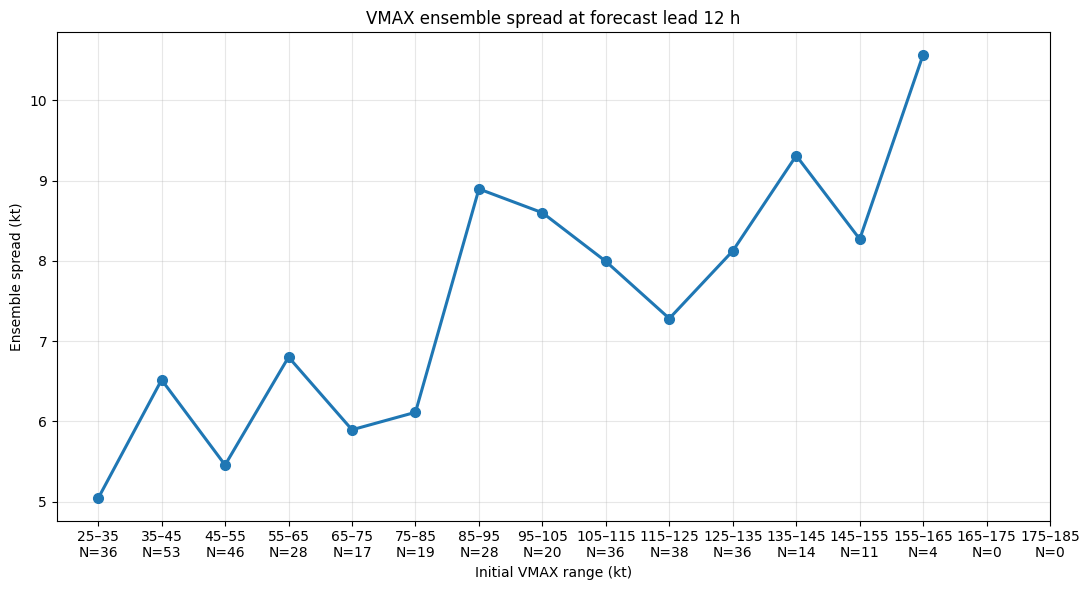

In [11]:
models = ["HWRF", "HFSA", "HMON", "HFSB"]
metric = "VMAX"
storms = ["aep112026.dat", "aep122026.dat", "aep172026.dat", "aep072026.dat", "aep112025.dat",
          "awp042026.dat", "awp092026.dat", "awp122026.dat", "awp242025.dat",
          "aal082025.dat", "aal132025.dat", "aal022024.dat", "aal122024.dat",]
lead_time = 12
initial_intensity_values = list(range(30, 181, 10))

spread, n_cases = verification.compute_ensemble_spread(
    models=models,
    metric=metric,
    storms=storms,
    lead_time=lead_time,
    initial_intensity_values=initial_intensity_values,
)
print("Cases by initial-intensity range:")
for center, count, value in zip(
    initial_intensity_values, n_cases, spread
):
    print(f"  {center - 5:g}–{center + 5:g}: N={count}, spread={value:.3f}")

fig, ax = plot_initial_intensity_ensemble_spread(
    initial_intensity_values=initial_intensity_values,
    spread=spread,
    n_cases=n_cases,
    metric=metric,
    lead_time=lead_time,
)